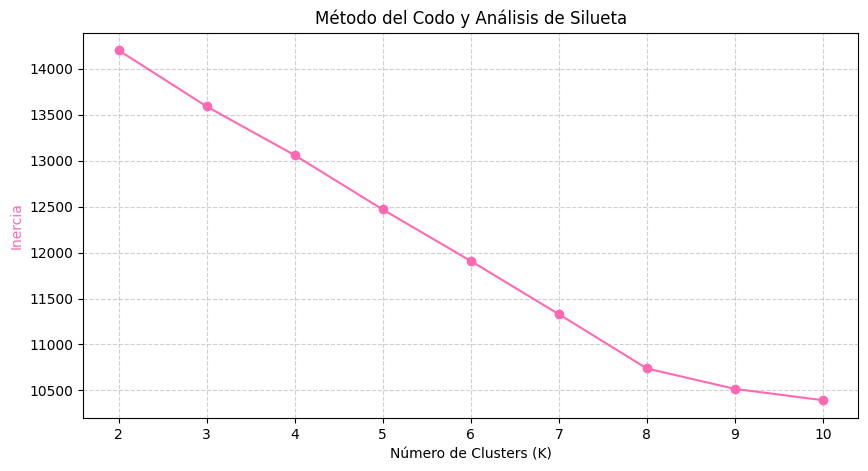

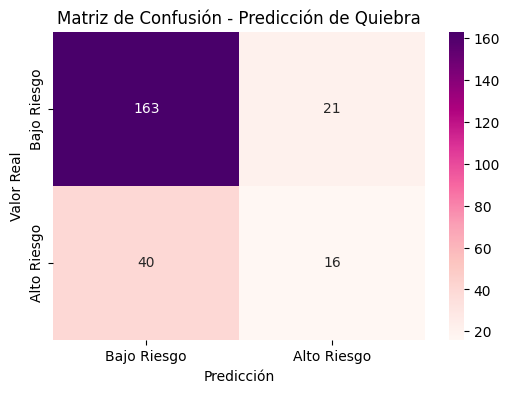

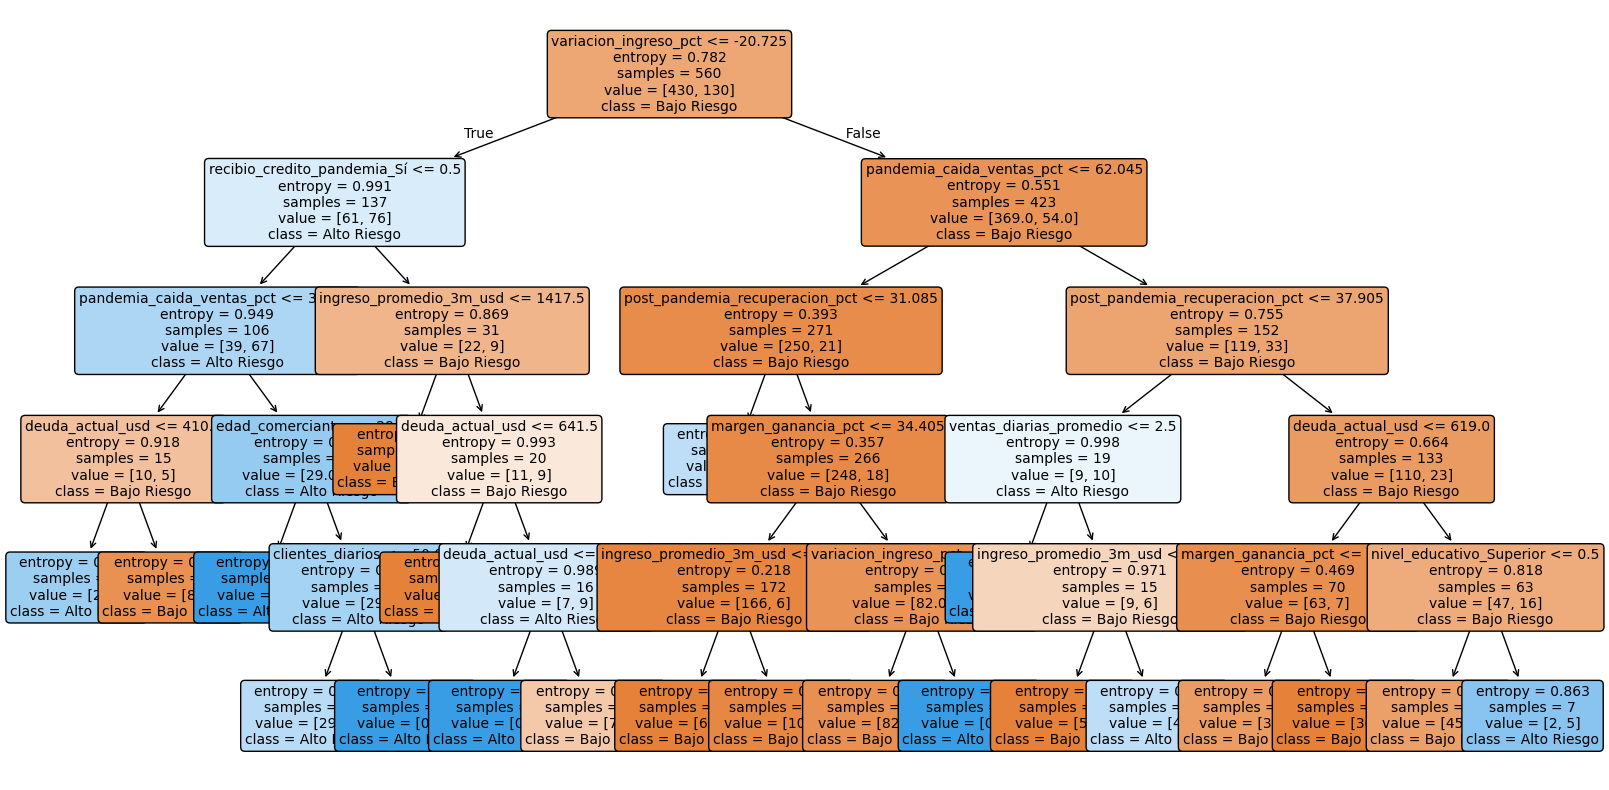

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc

#KMEANS
df_kmeans = pd.read_csv('datasets/comerciantes_mercado.csv')
#eliminar ids que no sirven para el modelo
df_kmeans_clean = df_kmeans.drop(['comerciante_id', 'nombre_negocio'], axis=1)
#convertir variables
binarias = ['tiene_almacen', 'vende_online', 'acepta_tarjeta', 'horario_extendido']
for col in binarias:
    df_kmeans_clean[col] = df_kmeans_clean[col].map({'Sí': 1, 'No': 0})

df_kmeans_encoded = pd.get_dummies(df_kmeans_clean)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_kmeans_encoded)

#metodo del codo y silueta
inercia = []
silueta = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    inercia.append(kmeans.inertia_)
    silueta.append(silhouette_score(X_scaled, kmeans.labels_))
#grafica
plt.close('all')
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(K_range, inercia, marker='o', color='hotpink', label='Inercia (Codo)')
ax1.set_xlabel('Número de Clusters (K)')
ax1.set_ylabel('Inercia', color='hotpink')
plt.title('Método del Codo y Análisis de Silueta')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


#ARBOL DE RIESGO DE QUIEBRA
df_tree = pd.read_csv('datasets/quiebra_mercado.csv')

#one hot encoding
categoricas = ['rubro', 'ubicacion', 'nivel_educativo', 'tiene_seguro', 'recibio_credito_pandemia']
df_tree_encoded = pd.get_dummies(df_tree, columns=categoricas, drop_first=True)

X = df_tree_encoded.drop(['registro_id', 'comerciante_id', 'quiebra_6m'], axis=1)
y = df_tree_encoded['quiebra_6m']

#división 70/30 estratificada
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)

arbol = DecisionTreeClassifier(criterion='entropy', max_depth=5, min_samples_split=10, random_state=42)
arbol.fit(X_train, y_train)


y_pred = arbol.predict(X_test)
y_prob = arbol.predict_proba(X_test)[:, 1]

#matriz de confusion
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='RdPu',
            xticklabels=['Bajo Riesgo', 'Alto Riesgo'],
            yticklabels=['Bajo Riesgo', 'Alto Riesgo'])
plt.title('Matriz de Confusión - Predicción de Quiebra')
plt.ylabel('Valor Real')
plt.xlabel('Predicción')
plt.show()

plt.figure(figsize=(20,10))
plot_tree(arbol, feature_names=X.columns, class_names=['Bajo Riesgo', 'Alto Riesgo'],
          filled=True, rounded=True, fontsize=10)
plt.show()







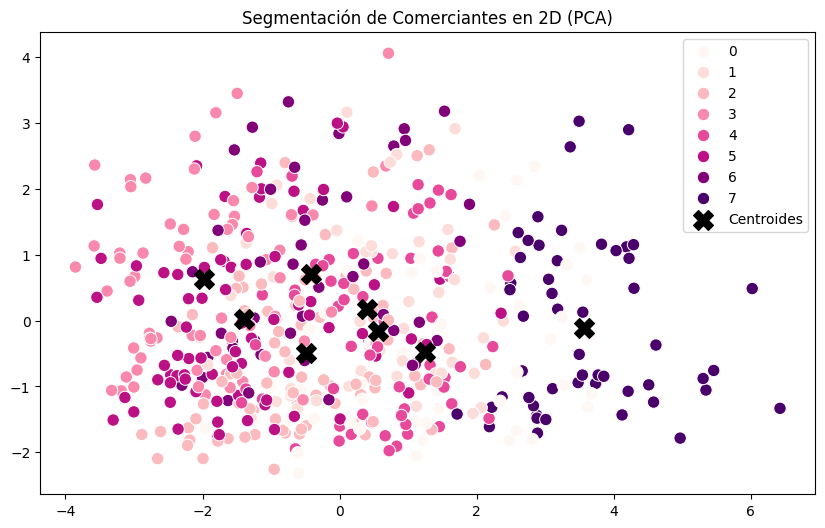

Reporte de Clasificación:
              precision    recall  f1-score   support

 Bajo Riesgo       0.80      0.89      0.84       184
 Alto Riesgo       0.43      0.29      0.34        56

    accuracy                           0.75       240
   macro avg       0.62      0.59      0.59       240
weighted avg       0.72      0.75      0.73       240



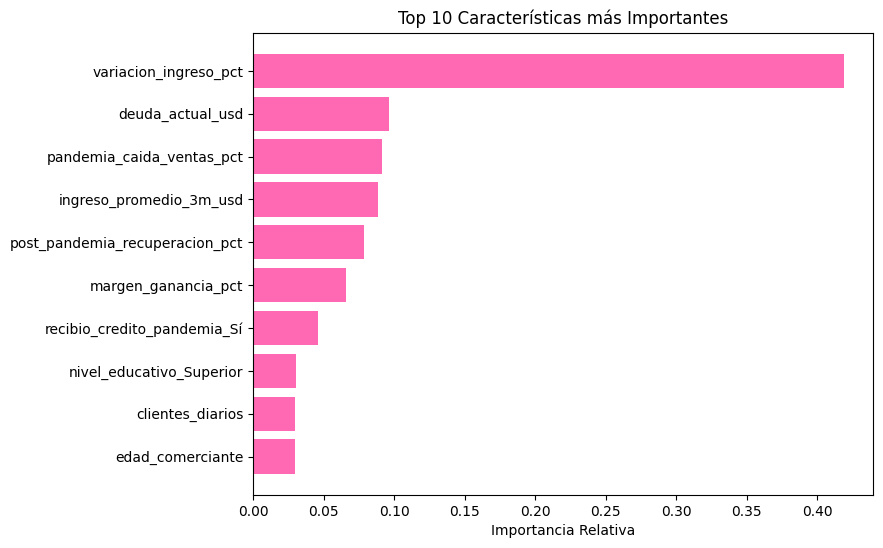

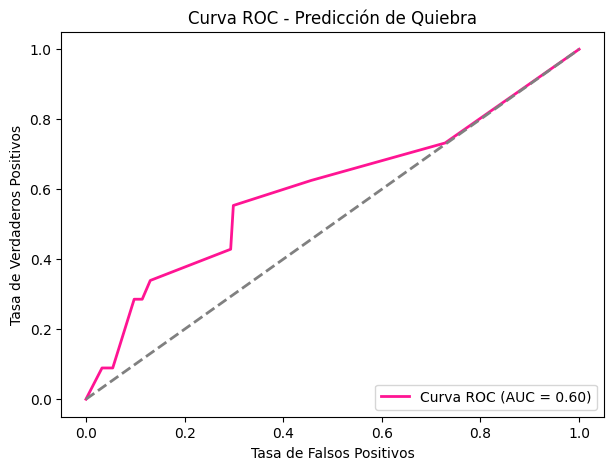

In [7]:

#KMEANS
kmeans_final = KMeans(n_clusters=8, init='k-means++', random_state=42)
y_kmeans = kmeans_final.fit_predict(X_scaled)

# reducimos a 2D con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
centroides_pca = pca.transform(kmeans_final.cluster_centers_)

#grafica
plt.close('all')
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_kmeans, palette='RdPu', s=80, legend='full')
plt.scatter(centroides_pca[:, 0], centroides_pca[:, 1], s=200, c='black', marker='X', label='Centroides')
plt.title('Segmentación de Comerciantes en 2D (PCA)')
plt.legend()
plt.show()


#ARBOL
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=['Bajo Riesgo', 'Alto Riesgo']))

# grafico de importancia de variables
importancias = arbol.feature_importances_
indices = np.argsort(importancias)[-10:] # Tomamos las top 10

plt.figure(figsize=(8, 6))
plt.barh(range(len(indices)), importancias[indices], color='hotpink', align='center')
plt.yticks(range(len(indices)), [X.columns[i] for i in indices])
plt.xlabel('Importancia Relativa')
plt.title('Top 10 Características más Importantes')
plt.show()

#curva ROC con AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='deeppink', lw=2, label=f'Curva ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--') # Línea diagonal
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC - Predicción de Quiebra')
plt.legend(loc='lower right')
plt.show()

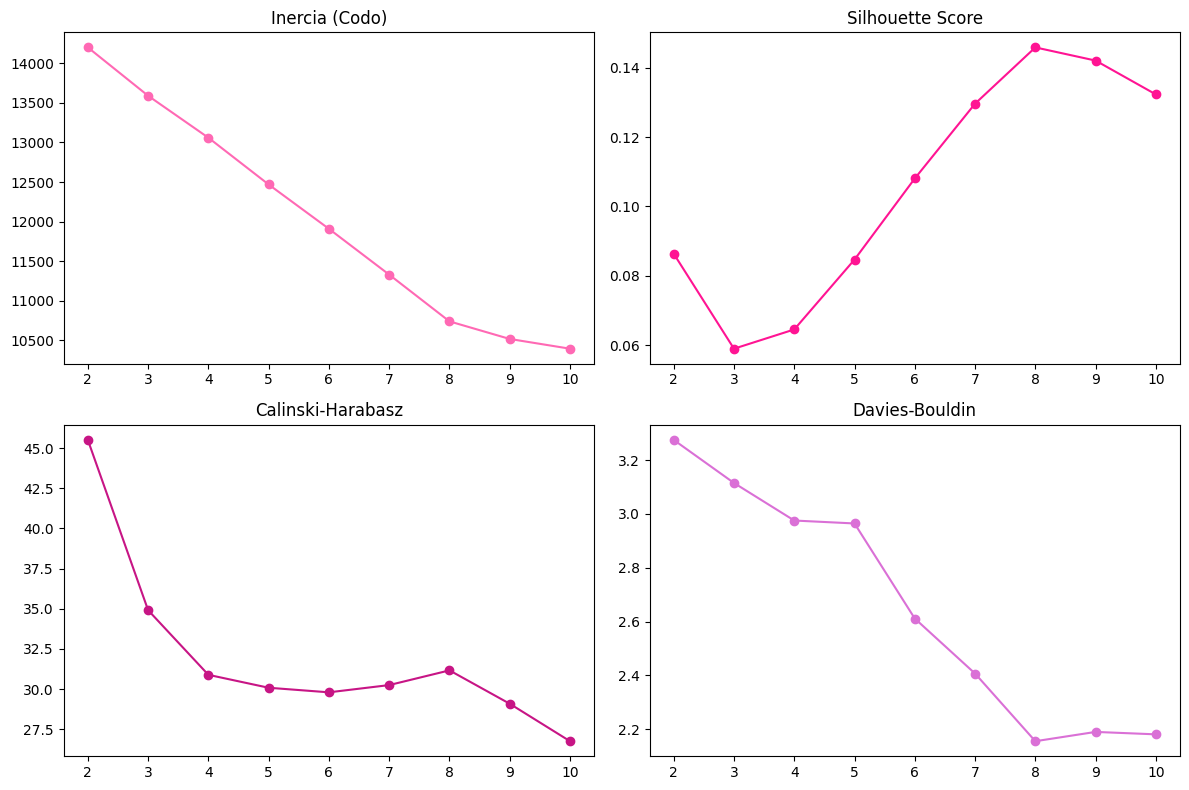


--- Tabla de Perfilamiento de Clusters ---
         Tamaño  Ingreso_Prom_USD  Edad_Prom  Antiguedad_Prom  Pct_Tarjeta  \
Cluster                                                                      
0            55           3135.05      42.67            11.55         0.53   
1            50           2687.64      45.02             9.94         0.40   
2            91           2361.69      45.79             9.98         0.31   
3            68           1576.82      42.72            11.26         0.15   
4            60           2742.83      43.37             5.35         0.33   
5            78           1880.56      43.76             9.36         0.24   
6            46           2257.13      43.00            11.57         0.35   
7            52           4351.29      41.96            20.08         0.56   

         Pct_Online  
Cluster              
0              0.36  
1              0.38  
2              0.23  
3              0.12  
4              0.38  
5              0.32  

In [8]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score
import numpy as np

#Calinski y Davies para el gráfico 2x2
calinski = []
davies = []
for k in K_range:
    km_eval = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km_eval.fit(X_scaled)
    calinski.append(calinski_harabasz_score(X_scaled, km_eval.labels_))
    davies.append(davies_bouldin_score(X_scaled, km_eval.labels_))

# grafico 2x2
plt.close('all')
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs[0,0].plot(K_range, inercia, marker='o', color='hotpink')
axs[0,0].set_title('Inercia (Codo)')
axs[0,1].plot(K_range, silueta, marker='o', color='deeppink')
axs[0,1].set_title('Silhouette Score')
axs[1,0].plot(K_range, calinski, marker='o', color='mediumvioletred')
axs[1,0].set_title('Calinski-Harabasz')
axs[1,1].plot(K_range, davies, marker='o', color='orchid')
axs[1,1].set_title('Davies-Bouldin')
plt.tight_layout()
plt.show()

#tbla de perfilamiento de Clusters
df_kmeans_clean['Cluster'] = y_kmeans
tabla_perfil = df_kmeans_clean.groupby('Cluster').agg(
    Tamaño=('ingreso_mensual_usd', 'count'),
    Ingreso_Prom_USD=('ingreso_mensual_usd', 'mean'),
    Edad_Prom=('edad_comerciante', 'mean'),
    Antiguedad_Prom=('anios_operacion', 'mean'),
    Pct_Tarjeta=('acepta_tarjeta', 'mean'), # Promedio de 1s y 0s nos da el porcentaje
    Pct_Online=('vende_online', 'mean')
).round(2)
print("\n--- Tabla de Perfilamiento de Clusters ---")
print(tabla_perfil)

#analisis de estabilidad (20 inicializaciones)
inercias_20 = []
for i in range(20):
    km_estab = KMeans(n_clusters=8, init='random', n_init=1, random_state=i)
    km_estab.fit(X_scaled)
    inercias_20.append(km_estab.inertia_)

print("\n Analisis de Estabilidad ")
print(f"Desviación estándar de la inercia (20 inits): {np.std(inercias_20):.2f}")